# Data Exploration: ROGII - Wellbore Geology Prediction | [Kaggle](https://www.kaggle.com/competitions/rogii-wellbore-geology-prediction/)
 1. [Training Data](#1-Training-Data)
    1. Horizontal Well CSV
        1. [Sample Well](#a-Sample-HW)
        2. [Across Wells](#b-HW-Across-Wells)
        3. Across Wells of the same class (using similar typewells - covered in layers notebook)
    2. Type Well CSV
        1. [Sample Well & Against Corresponding Horizontal Well](#a-Sample-TW)
        2. [Across Wells](#b-TW-Across-Wells)
        3. Across wells of the same class.
    3. Picture: [Thread](https://www.kaggle.com/competitions/rogii-wellbore-geology-prediction/discussion/705210)
 2. [Test](#Testing-Data)
     1. Horizontal Well
     2. Type Well

In [1]:
import os
import glob
import numpy as np
np.random.seed(1234567)
import pandas as pd

import matplotlib.pyplot as plt
import matplotlib.image as mpimg

import re
import warnings
warnings.filterwarnings('ignore')

In [2]:
# Automatically detect if running on Kaggle or Locally
IS_KAGGLE = os.path.exists('/kaggle/input')
BASE_DIR = '/kaggle/input/competitions/rogii-wellbore-geology-prediction' if IS_KAGGLE else '../data'

print(f"Running on {'Kaggle' if IS_KAGGLE else 'Local Environment'}")
print(f"Data Directory: {BASE_DIR}")

Running on Local Environment
Data Directory: ../data


---

## 1-Training-Data
>Each well has three associated files.
Each well is identified by a unique 8-character hash (e.g., `015fe0d2`).

In [3]:
train_data = os.path.join(BASE_DIR, "train")
file_paths = sorted(os.listdir(train_data))
file_paths[:10]

['.DS_Store',
 '000d7d20.png',
 '000d7d20__horizontal_well.csv',
 '000d7d20__typewell.csv',
 '00bbac68.png',
 '00bbac68__horizontal_well.csv',
 '00bbac68__typewell.csv',
 '00e12e8b.png',
 '00e12e8b__horizontal_well.csv',
 '00e12e8b__typewell.csv']

In [4]:
# Regex pattern: 
pattern = re.compile(r'([^/\\]+)__horizontal_well\.csv')

well_names = []
for path in file_paths:
    match = pattern.search(path)
    if match:
        well_names.append(match.group(1))

print("Extracted Well Names:")
print(len(well_names), "Well Names")
print("Every Well Name has 3 files: ")
print(len(file_paths) / 3 == len(well_names))

Extracted Well Names:
773 Well Names
Every Well Name has 3 files: 
False


In [5]:
sample_well = np.random.choice(well_names)

horizontal_well_csv = pd.read_csv(train_data + f"/{sample_well}__horizontal_well.csv")
typewell_csv = pd.read_csv(train_data + f"/{sample_well}__typewell.csv")
pic = train_data + f"/{sample_well}.png"

sample_well, horizontal_well_csv.shape, typewell_csv.shape

(np.str_('8b95d6d1'), (2783, 13), (1245, 3))

### a-Sample-HW

In [6]:
horizontal_well_csv.head()

,MD,X,Y,Z,ANCC,ASTNU,ASTNL,EGFDU,EGFDL,BUDA,TVT,GR,TVT_input
0,10482.0,2945499.17,1069891.92,-8279.33,-8369.82,-8525.78,-8602.53,-8692.11,-8736.81,-8841.87,10271.92,99.579226,10271.92
1,10483.0,2945499.18,1069891.91,-8280.33,-8369.82,-8525.78,-8602.53,-8692.11,-8736.81,-8841.87,10272.92,101.281828,10272.92
2,10484.0,2945499.18,1069891.90,-8281.33,-8369.82,-8525.78,-8602.53,-8692.11,-8736.81,-8841.87,10273.92,99.579226,10273.92
3,10485.0,2945499.19,1069891.89,-8282.33,-8369.82,-8525.78,-8602.53,-8692.11,-8736.81,-8841.87,10274.92,106.941830,10274.92
4,10486.0,2945499.19,1069891.87,-8283.33,-8369.82,-8525.78,-8602.53,-8692.11,-8736.81,-8841.87,10275.92,NaN,10275.92


In [7]:
horizontal_well_csv.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2783 entries, 0 to 2782
Data columns (total 13 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   MD         2783 non-null   float64
 1   X          2783 non-null   float64
 2   Y          2783 non-null   float64
 3   Z          2783 non-null   float64
 4   ANCC       2783 non-null   float64
 5   ASTNU      2783 non-null   float64
 6   ASTNL      2783 non-null   float64
 7   EGFDU      2783 non-null   float64
 8   EGFDL      2783 non-null   float64
 9   BUDA       2783 non-null   float64
 10  TVT        2783 non-null   float64
 11  GR         1663 non-null   float64
 12  TVT_input  1052 non-null   float64
dtypes: float64(13)
memory usage: 282.8 KB


In [8]:
mask = horizontal_well_csv['TVT_input'].isna()
evalz = horizontal_well_csv[mask]

In [9]:
display("MD differes by 1 feet at every index:")
(horizontal_well_csv['MD'].diff().dropna() == 1).all()

'MD differes by 1 feet at every index:'

np.True_

Data is Multi-Collinear:

<Axes: >

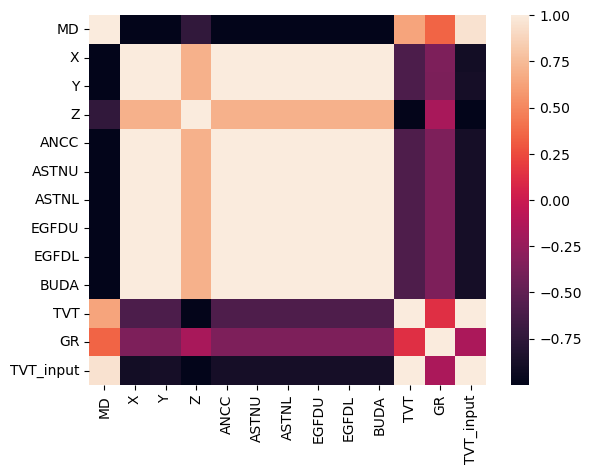

In [10]:
import seaborn as sns
hw = horizontal_well_csv.copy()
hw['X'] *= -1
sns.heatmap(hw.corr())

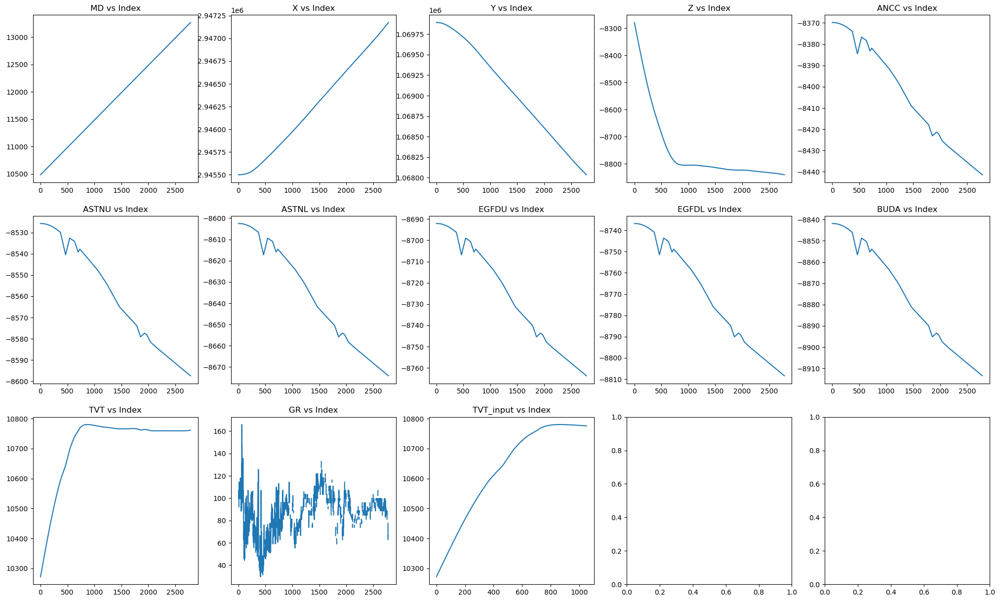

In [11]:
# Plotting all the graphs at a glance

num_cols = len(horizontal_well_csv.columns)
fig, ax = plt.subplots(3, num_cols//3 + 1, figsize=(25, 15))
ax = ax.flatten()

for i, col in enumerate(horizontal_well_csv.columns):
    ax[i].plot(horizontal_well_csv[col])
    ax[i].set_title(f"{col} vs Index")

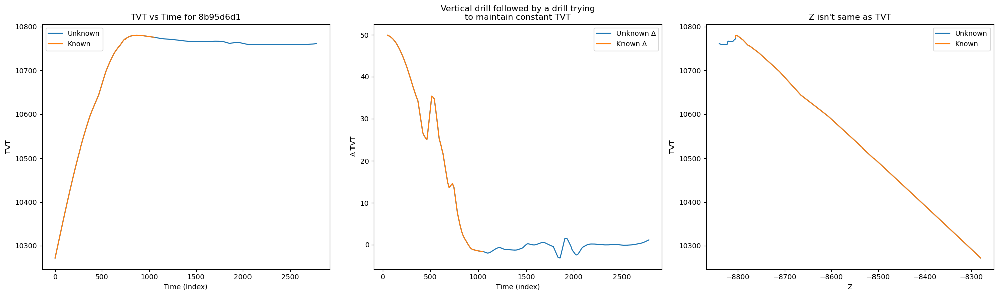

'First |Z| and |T| both increase, then TVT remains constant in the horizontal part of the drill'

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(20, 6))

axes[0].plot(horizontal_well_csv['TVT'], label='Unknown')
axes[0].plot(horizontal_well_csv['TVT_input'], label='Known')
axes[0].set_title(f"TVT vs Time for {sample_well}")
axes[0].set_xlabel('Time (Index)')
axes[0].set_ylabel('TVT')
axes[0].legend()

tvt_steps = horizontal_well_csv['TVT'].diff(50).dropna()
tvt_steps_i = horizontal_well_csv['TVT_input'].diff(50).dropna()
axes[1].plot(tvt_steps, label='Unknown ∆')
axes[1].plot(tvt_steps_i, label='Known ∆')
axes[1].set_title("Vertical drill followed by a drill trying\nto maintain constant TVT") 
axes[1].set_xlabel('Time (index)')
axes[1].set_ylabel('∆ TVT')
axes[1].legend()

axes[2].plot(horizontal_well_csv['Z'], horizontal_well_csv['TVT'], label='Unknown')
axes[2].plot(horizontal_well_csv['Z'], horizontal_well_csv['TVT_input'], label='Known')
axes[2].set_title("Z isn't same as TVT")
axes[2].set_xlabel('Z')
axes[2].set_ylabel('TVT')
axes[2].legend()

# 3. Adjust spacing and render
plt.tight_layout()
plt.show()

# 4. Print your final observation below the graphs
display("First |Z| and |T| both increase, then TVT remains constant in the horizontal part of the drill")

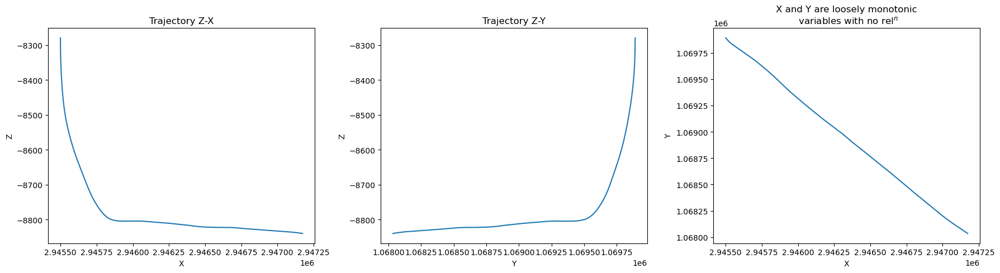

In [13]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

axes[0].plot(horizontal_well_csv['X'], horizontal_well_csv['Z'])
axes[0].set_title('Trajectory Z-X') 
axes[0].set_xlabel('X')
axes[0].set_ylabel('Z')

axes[1].plot(horizontal_well_csv['Y'], horizontal_well_csv['Z'])
axes[1].set_title('Trajectory Z-Y')
axes[1].set_xlabel('Y')
axes[1].set_ylabel('Z')

axes[2].plot(horizontal_well_csv['X'], horizontal_well_csv['Y'])
axes[2].set_title('X and Y are loosely monotonic\n variables with no rel$^n$')
axes[2].set_xlabel('X')
axes[2].set_ylabel('Y')

plt.tight_layout()

plt.show()

In [14]:
# TVT_input is same as TVT if not nan

mask = horizontal_well_csv['TVT_input'].notna()
display("TVT_input is same as TVT if not nan: ")
display((horizontal_well_csv['TVT'][mask] == horizontal_well_csv['TVT_input'][mask]).all())
display("% Filled: ")
display(100 * mask.sum() / len(mask))

'TVT_input is same as TVT if not nan: '

np.True_

'% Filled: '

np.float64(37.80093424362199)

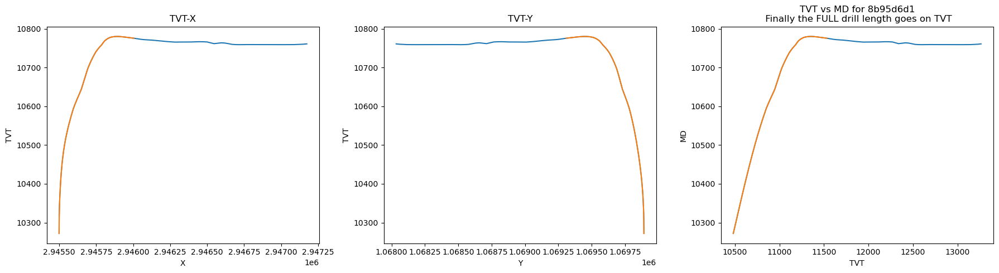

In [15]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

axes[0].plot(horizontal_well_csv['X'], horizontal_well_csv['TVT'])
axes[0].plot(horizontal_well_csv['X'], horizontal_well_csv['TVT_input'])
axes[0].set_title('TVT-X')
axes[0].set_xlabel('X')
axes[0].set_ylabel('TVT')

axes[1].plot(horizontal_well_csv['Y'], horizontal_well_csv['TVT'])
axes[1].plot(horizontal_well_csv['Y'], horizontal_well_csv['TVT_input'])
axes[1].set_title('TVT-Y')
axes[1].set_xlabel('Y')
axes[1].set_ylabel('TVT')

axes[2].plot(horizontal_well_csv['MD'], horizontal_well_csv['TVT'])
axes[2].plot(horizontal_well_csv['MD'], horizontal_well_csv['TVT_input'])
axes[2].set_title(f'TVT vs MD for {sample_well}\n Finally the FULL drill length goes on TVT')
axes[2].set_xlabel('TVT')
axes[2].set_ylabel('MD')

plt.tight_layout()

plt.show()

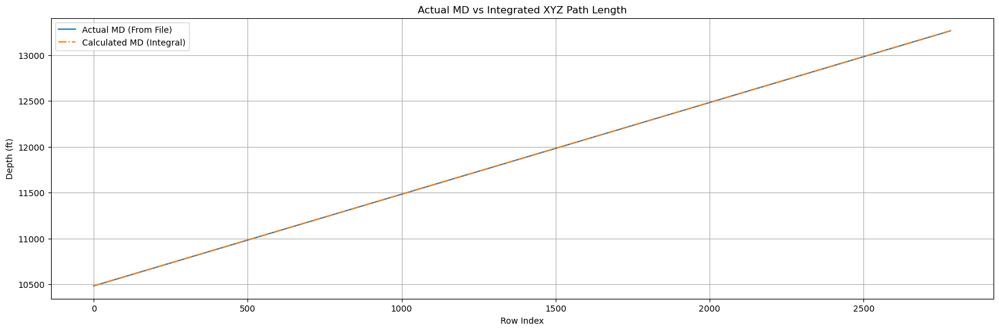

In [16]:
dx = horizontal_well_csv['X'].diff().fillna(0)
dy = horizontal_well_csv['Y'].diff().fillna(0)
dz = horizontal_well_csv['Z'].diff().fillna(0)

m = np.sqrt(dx**2 + dy**2 + dz**2).cumsum() + horizontal_well_csv['MD'].iloc[0] 


# 4. Plotting
plt.figure(figsize=(20, 6))

# Plot Actual MD vs Calculated MD
plt.plot(horizontal_well_csv['MD'], label='Actual MD (From File)')
plt.plot(m, label='Calculated MD (Integral)', linestyle='dashdot')

plt.title('Actual MD vs Integrated XYZ Path Length')
plt.xlabel('Row Index')
plt.ylabel('Depth (ft)')
plt.legend()
plt.grid(True)
plt.show()

np.float64(-0.9487004103967165)

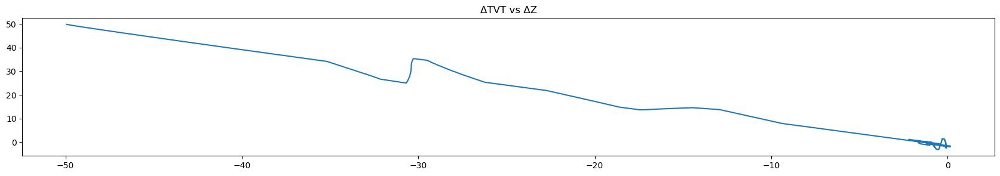

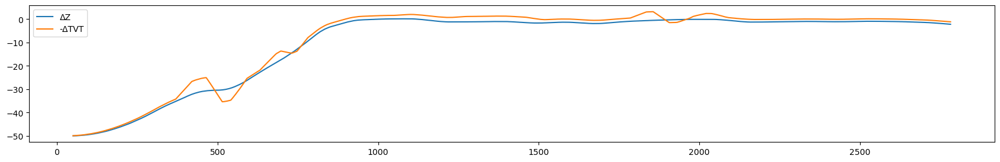

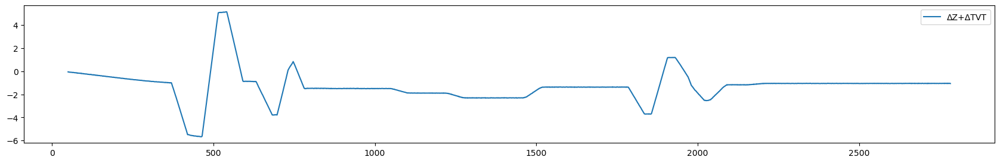

In [17]:
plt.figure(figsize=(21, 3))
diff_z = horizontal_well_csv['Z'].diff(50)
diff_tvt = horizontal_well_csv['TVT'].diff(50)
plt.plot(diff_z, diff_tvt)
plt.title('ΔTVT vs ΔZ')

plt.figure(figsize=(21, 3))
plt.plot(diff_z, label='ΔZ')
plt.plot(-diff_tvt, label='-ΔTVT')
plt.legend()

plt.figure(figsize=(21, 3))
plt.plot(diff_z+diff_tvt, label='ΔZ+ΔTVT')
plt.legend()

np.median((diff_z / diff_tvt).dropna())

### b-HW-Across-Wells

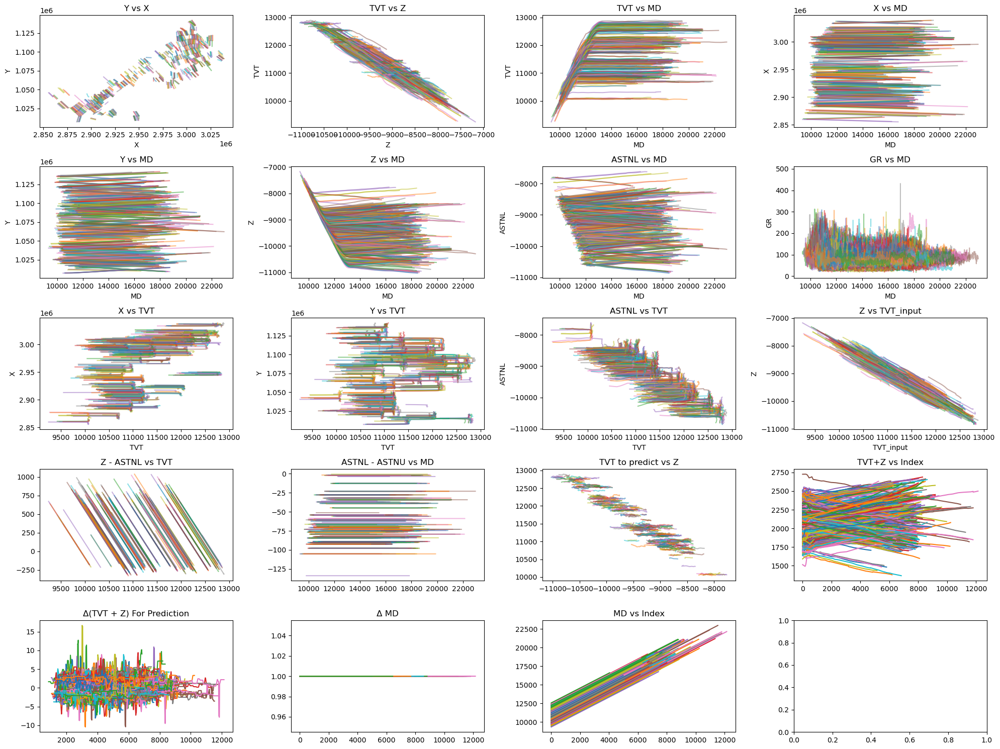

In [18]:
# Plotting Graphs across wells.

plot_pairs = [
    ('X', 'Y'), ('Z', 'TVT'), ('MD', 'TVT'), 
    ('MD', 'X'), ('MD', 'Y'), ('MD', 'Z'), 
    ('MD', 'ASTNL'), ('MD', 'GR'), ('TVT', 'X'), 
    ('TVT', 'Y'), ('TVT', 'ASTNL'), ('TVT_input', 'Z')
]

# Create a 3x4 grid of subplots
fig, axes = plt.subplots(nrows=5, ncols=4, figsize=(20, 15))
axes = axes.flatten() # Flatten the 2D array of axes for easy iteration

for well in well_names:
    # if well == '3c3dbcbc':
    #     continue # Skip the well with weird gradient issues
        
    file_path = f"{train_data}/{well}__horizontal_well.csv"
    hw = pd.read_csv(file_path)
    
    # Loop through the pairs and plot them on their respective subplots
    for ax, (x_col, y_col) in zip(axes, plot_pairs):
        # Using alpha=0.5 makes overlapping lines easier to see
        ax.plot(hw[x_col], hw[y_col], alpha=0.5) 
        ax.set_title(f"{y_col} vs {x_col}")
        ax.set_xlabel(x_col)
        ax.set_ylabel(y_col)

    axes[12].plot(hw['TVT'], hw['Z'] - hw['ASTNL'], alpha=0.5)
    axes[12].set_title("Z - ASTNL vs TVT")
    
    axes[13].plot(hw['MD'], hw['ASTNL'] - hw['ASTNU'], alpha=0.5)
    axes[13].set_title("ASTNL - ASTNU vs MD")
    
    prediction_mask = np.isnan(hw['TVT_input'])
    axes[14].plot(hw['Z'][prediction_mask], hw['TVT'][prediction_mask], alpha=0.5)
    axes[14].set_title("TVT to predict vs Z")
    
    axes[15].plot(hw['Z'] + hw['TVT'])
    axes[15].set_title("TVT+Z vs Index")
    
    axes[16].plot(((hw['Z'] + hw['TVT']).diff(50))[prediction_mask].rolling(window=15, center=True, min_periods=1).mean())
    axes[16].set_title("Δ(TVT + Z) For Prediction")
    
    axes[17].plot(hw['MD'].diff().dropna())
    axes[17].set_title("Δ MD")
    
    axes[18].plot(hw['MD'])
    axes[18].set_title("MD vs Index")

# Adjust layout so titles and labels don't overlap
plt.tight_layout()
plt.show()

In [19]:
# Finding how much is already labeled

l = []
k = []
for well in well_names:
    hw = pd.read_csv(train_data + f"/{well}__horizontal_well.csv")
    mask = hw['TVT_input'].isna()
    evalz = hw[mask]
    l.append(len(hw))
    k.append(len(evalz) / len(hw))
l = np.array(l)
k = np.array(k)
(l.mean(), l.std(), l.min(), l.max(),
k.mean(), k.std(), k.min(), k.max())

(np.float64(6587.652005174644),
 np.float64(1310.6149773574725),
 np.int64(2058),
 np.int64(12141),
 np.float64(0.7331608207804735),
 np.float64(0.0637343419618474),
 np.float64(0.19776482021379982),
 np.float64(0.8751648351648351))

### Linear approximation between TVT = a + b * Z + c * MD
The most striking pattern in this data is how incredibly accurate this simple 2-variable per-well linear regression is for almost the entire dataset:
* 21 wells have an RMSE of less than 2 feet.
* 265 wells have an RMSE of less than 5 feet.
* 666 wells (86% of the dataset) have an RMSE of less than 10 feet.
* Total RMSE of about 3.773
* This isn't exact (unlike layers) but good to notice

In [20]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import root_mean_squared_error

In [21]:
meta_weights = []

print(f"Extracting weights for {len(well_names)} wells...")

for well in well_names:
    file_path = f"{train_data}/{well}__horizontal_well.csv"
    
    # Load the file
    hw_ = pd.read_csv(file_path)

    # Prediction mask
    mask = np.isnan(hw_['TVT_input'])
    hw = hw_[mask]
    
    # Only use geometric variables
    features = ['X', 'Y', 'Z']
    target = 'TVT'
    
    # Clean data (drop rows where TVT, Z, or MD are missing)
    df_clean = hw.dropna(subset=[target] + features)
    
    # If the file has no valid TVT rows, skip it so the loop doesn't crash
    if len(df_clean) < 2:
        print(f"Skipping {well}: Not enough valid data.")
        continue
        
    X = df_clean[features]
    y = df_clean[target]
    
    # Fit model
    model = LinearRegression()
    model.fit(X, y)
    
    # Calculate Metrics
    r2_score = model.score(X, y)
    
    # We can use model.predict() directly instead of writing the math out manually!
    y_pred = model.predict(X) 
    rmse = root_mean_squared_error(y, y_pred)
    
    meta_weights.append({
        'Well_ID': well,
        'Intercept': model.intercept_,
        'X_Coef': model.coef_[0],
        'Y_Coef': model.coef_[1],
        'Z_Coef': model.coef_[2],
        'R2_Score': r2_score,
        'RMSE': rmse,
        'len': len(y)
    })

# Convert the list of dictionaries into a Pandas DataFrame
weights_df = pd.DataFrame(meta_weights)

# Save the extracted weights to a CSV so you don't have to run the loop again
weights_df.to_csv("../data/master_well_weights_4.csv", index=False)

print("\nExtraction Complete! Here is your Meta-DataFrame:")
display(weights_df.head())

Extracting weights for 773 wells...

Extraction Complete! Here is your Meta-DataFrame:


,Well_ID,Intercept,X_Coef,Y_Coef,Z_Coef,R2_Score,RMSE,len
0,000d7d20,4.245497e+05,-0.142378,0.006882,-0.474915,0.964457,0.959732,3836
1,00bbac68,3.413511e+05,-0.097934,-0.044876,-1.413271,0.951510,3.314812,6014
2,00e12e8b,9.690529e+05,-0.265778,-0.164663,-0.728837,0.836305,3.191440,4301
3,015fe0d2,-1.783821e+06,0.459968,0.378721,-0.862331,0.880403,4.180132,4296
4,01869cd4,-1.380695e+05,0.024164,0.063706,-1.057358,0.866516,3.519443,5557


In [22]:
np.sqrt(np.sum(np.pow(weights_df['RMSE'], 2) * weights_df['len']) / np.sum(weights_df['len']))

np.float64(3.7735391323103387)

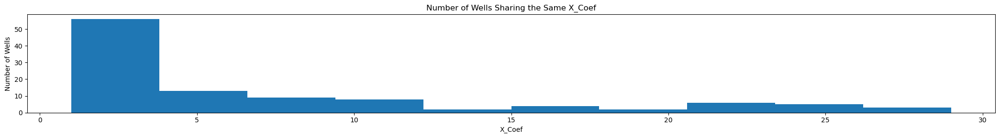

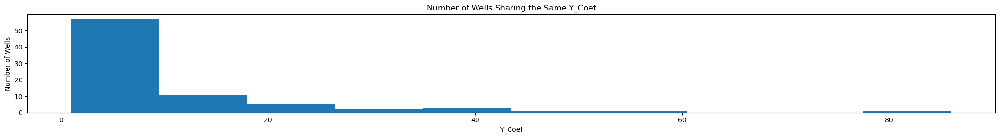

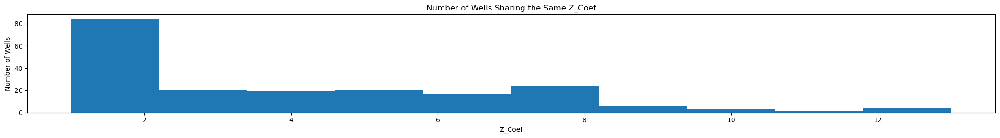

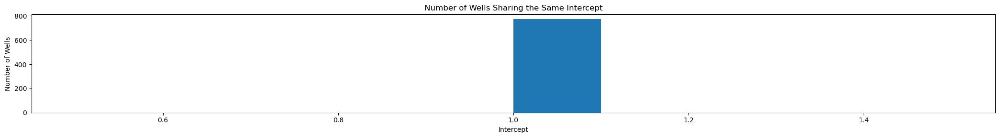

In [23]:
coeffs = ['X_Coef', 'Y_Coef', 'Z_Coef', 'Intercept']
for coef in coeffs:
    k1_counts = np.round(weights_df[[coef]], 2).value_counts().sort_index()
    
    # 2. Plot the bar graph
    plt.figure(figsize=(21, 3))
    # k1_counts.plot(kind='bar')
    plt.hist(k1_counts)
    
    # 3. Add labels and title
    plt.title(f'Number of Wells Sharing the Same {coef}')
    plt.xlabel(coef)
    plt.ylabel('Number of Wells')
    
    # Adjust layout to fit everything nicely
    plt.tight_layout()
    plt.show()

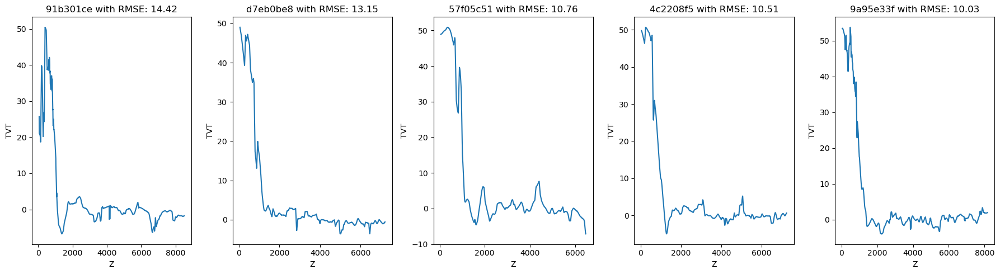

In [24]:
# Trying to understand why these have such a high RMSE, average RMSE is 6

fig, axes = plt.subplots(1, 5, figsize=(18, 5))

for i, (well, rmse) in enumerate(zip(weights_df.nlargest(5, 'RMSE')['Well_ID'], weights_df.nlargest(5, 'RMSE')['RMSE'])):
    hw = pd.read_csv(train_data + f"/{well}__horizontal_well.csv")
    # axes[i].plot(hw['MD'], hw['TVT'])
    # axes[i].plot(hw['Z'].diff().dropna(), hw['TVT'].diff().dropna())
    axes[i].plot(hw['TVT'].diff(50).dropna())
    # axes[i].plot(hw['Z'].diff().dropna(), hw['TVT_input'].diff().dropna())
    
    axes[i].set_title(f'{well} with RMSE: {rmse:.2f}')
    axes[i].set_xlabel('Z')
    axes[i].set_ylabel('TVT')
plt.tight_layout()
plt.show()

In [25]:
import plotly.graph_objects as go

# Assuming your dataframe is named horizontal_well_csv
df = horizontal_well_csv

# Create the base figure
fig = go.Figure()

# ---------------------------------------------------------
# 1. Plot the actual wellbore path (The Drill Bit's Journey)
# ---------------------------------------------------------
fig.add_trace(go.Scatter3d(
    x=df['X'],
    y=df['Y'],
    z=df['Z'],
    mode='markers+lines',
    # Color the well path by Gamma Ray to see the "hot" shale!
    marker=dict(
        size=4,
        color=df['GR'].interpolate(),          
        colorscale='Jet',        # Creates a Blue -> Red heat map
        colorbar=dict(title="Gamma Ray (API)", x=-0.1),
        showscale=True
    ),
    line=dict(color='darkgrey', width=2),
    name='Actual Well Path'
))

# ---------------------------------------------------------
# 2. Plot the Geological Formations (The Map)
# ---------------------------------------------------------
formations = ['ANCC', 'ASTNU', 'ASTNL', 'EGFDU', 'EGFDL', 'BUDA']
colors = ['purple', 'lightblue', 'blue', 'orange', 'red', 'brown']

# Loop through each rock layer and draw its expected depth
for form, color in zip(formations, colors):
    fig.add_trace(go.Scatter3d(
        x=df['X'],
        y=df['Y'],
        z=df[form],  # Use the specific formation's depth column
        mode='lines',
        line=dict(color=color, width=3, dash='dot'),
        name=f'Top of {form}'
    ))

# ---------------------------------------------------------
# 3. Format the Layout
# ---------------------------------------------------------
fig.update_layout(
    title='3D Wellbore Trajectory vs. Geological Formations',
    scene=dict(
        xaxis_title='Easting (X)',
        yaxis_title='Northing (Y)',
        zaxis_title='TVD (Z)',
        
        # This prevents the Z-axis from stretching too wildly out of proportion
        aspectmode='manual',
        aspectratio=dict(x=1, y=1, z=0.4) 
    ),
    width=900,
    height=700,
    legend=dict(x=1.05, y=0.8) # Move legend slightly out of the way
)

# Display the interactive plot


fig.show()

In [26]:
# Expected non nan columns:

cls = ['MD', 'X', 'Y', 'Z', 'ANCC', 'ASTNU', 'ASTNL', 'EGFDU', 'EGFDL', 'BUDA', 'TVT']
nan_cells = set()
for well in well_names:
    well_csv = pd.read_csv(train_data + f"/{well}__horizontal_well.csv", usecols=cls)
    nan_rows = well_csv[well_csv.isna().any(axis=1)]
    for row_idx, row_data in nan_rows.iterrows():
        empty_columns = row_data[row_data.isna()].index.tolist()
        for col in empty_columns:
            nan_cells.add((well, col))

# At least one nan cell in the well:column group
print(nan_cells)

{('81bf5923', 'ANCC'), ('03a935ae', 'ANCC'), ('d7eb0be8', 'ANCC'), ('4c2208f5', 'ANCC'), ('1b1eba53', 'ANCC'), ('9dfff011', 'EGFDL'), ('a8ed028a', 'ANCC'), ('727a3a10', 'ANCC')}


## B-Typewell-CSV

### a-Sample-TW

In [27]:
typewell_csv.head() # First few in geology are empty

,TVT,GR,Geology
0,10259.65,106.17,NaN
1,10260.15,107.83,NaN
2,10260.65,106.19,NaN
3,10261.15,103.35,NaN
4,10261.65,102.03,NaN


In [28]:
typewell_csv.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1245 entries, 0 to 1244
Data columns (total 3 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   TVT      1245 non-null   float64
 1   GR       1245 non-null   float64
 2   Geology  1039 non-null   object 
dtypes: float64(2), object(1)
memory usage: 29.3+ KB


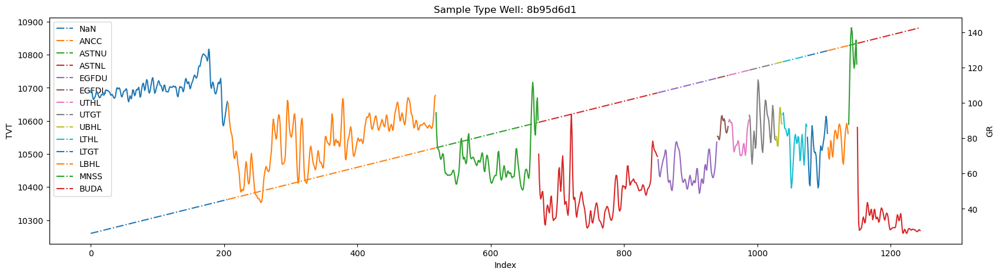

In [29]:
fig, ax1 = plt.subplots(figsize=(20, 5))
plt.title(f"Sample Type Well: {sample_well}")
plt.xlabel('Index')
ax2 = ax1.twinx()
ax1.set_ylabel('TVT')
ax2.set_ylabel('GR')
for layer in typewell_csv['Geology'].unique():
    if pd.isna(layer):
        layer_mask = typewell_csv['Geology'].isna()
        label = "NaN"
    else:
        layer_mask = typewell_csv['Geology'] == layer
        label = str(layer)
    ax1.plot(typewell_csv['TVT'][layer_mask], linestyle='-.', label=label)
    ax2.plot(typewell_csv['GR'][layer_mask], linestyle='solid', label=label)
ax1.legend()
plt.show()

In [30]:
typewell_csv['Geology'].unique()

array([nan, 'ANCC', 'ASTNU', 'ASTNL', 'EGFDU', 'EGFDL', 'UTHL', 'UTGT',
       'UBHL', 'LTHL', 'LTGT', 'LBHL', 'MNSS', 'BUDA'], dtype=object)

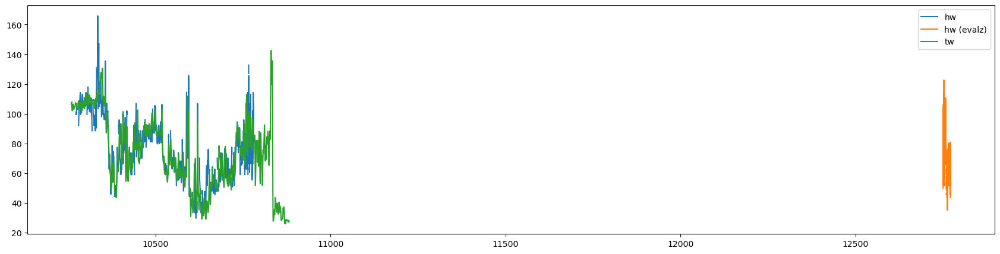

In [31]:
plt.figure(figsize=(21, 5))
plt.plot(horizontal_well_csv['TVT'], horizontal_well_csv['GR'], label='hw')
plt.plot(evalz['TVT'], evalz['GR'], label='hw (evalz)')
plt.plot(typewell_csv['TVT'], typewell_csv['GR'], label='tw')
plt.legend()

### b-TW-Across-Wells

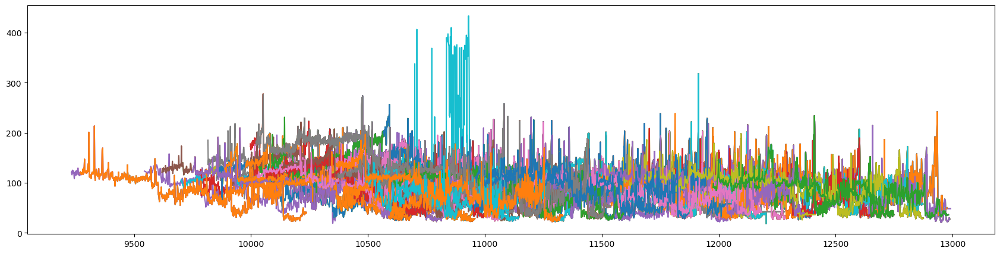

In [32]:
plt.figure(figsize=(21, 5))
for well in well_names:
    tw = pd.read_csv(f"{train_data}/{well}__typewell.csv")
    plt.plot(tw['TVT'], tw['GR'])

In [33]:
# 44 Geology Categories in Typewells for Geology

categories_geology = set()
for well in well_names:
    tw = pd.read_csv(f'{train_data}/{well}__typewell.csv')
    counts = tw['Geology'].value_counts(dropna=False)
    x_categories = counts.index.astype(str)
    categories_geology.update(x_categories)
len(categories_geology), list(categories_geology)[:5]

(44, ['UL_TGT', 'LL TGT', 'ULEF THL', 'BUDA', 'ASTNU'])

In [34]:
# Question: Do all typewells have the 6 master categories/ or can they be mapped to them? -> No and No. 

master = {'ANCC', 'ASTNU', 'ASTNL', 'EGFDU', 'EGFDL', 'BUDA'}
anamolies = dict()

for well in well_names:
    categories_geology = set()
    tw = pd.read_csv(f'{train_data}/{well}__typewell.csv')
    counts = tw['Geology'].value_counts(dropna=False)
    x_categories = counts.index.astype(str)
    categories_geology.update(x_categories)

    if not master.issubset(categories_geology):
        anamolies[well] = (master - categories_geology,
                           categories_geology - master)

anamolies

{'03a935ae': ({'ANCC'}, {'nan'}),
 '0bbf5e67': ({'BUDA'}, {'nan'}),
 '1b1eba53': ({'ANCC'}, {'nan'}),
 '2cee0cba': ({'BUDA'}, {'nan'}),
 '353e5502': ({'BUDA'}, {'nan'}),
 '4c2208f5': ({'ANCC'}, {'nan'}),
 '4f3eb9e9': ({'ANCC'}, set()),
 '4f4ac5ce': ({'BUDA'}, {'nan'}),
 '5aef5c6c': ({'BUDA'}, {'nan'}),
 '5d7198fd': ({'ANCC'}, {'MNSS'}),
 '5eae34a8': ({'BUDA'}, {'nan'}),
 '6e9ccd38': ({'ANCC'}, {'UPSN'}),
 '727a3a10': ({'ANCC'}, {'nan'}),
 '78a4a386': ({'ANCC'}, set()),
 '81bf5923': ({'ANCC'}, {'nan'}),
 '86454a6f': ({'ANCC', 'ASTNU'}, set()),
 '99529c45': ({'BUDA'}, {'nan'}),
 'a87433c9': ({'BUDA'}, {'nan'}),
 'a8ed028a': ({'ANCC'}, {'nan'}),
 'd00e7eb9': ({'BUDA'}, {'LL TGT', 'LL THL', 'nan'}),
 'd60430e6': ({'BUDA'}, {'nan'}),
 'd7eb0be8': ({'ANCC'}, {'nan'}),
 'd90aa14c': ({'BUDA'}, {'LL TGT', 'LL THL', 'nan'})}

In [35]:
# How many have extra values which aren't the 6 listed layers:
count = 0
total = 0
for well in well_names:
    categories_geology = set()
    tw = pd.read_csv(f'{train_data}/{well}__typewell.csv')
    counts = tw['Geology'].value_counts(dropna=False)
    x_categories = counts.index.astype(str)
    categories_geology.update(x_categories)
    if len(categories_geology - master) > 0:
        count+=1
    total+=1
        
count, total

(761, 773)

{np.float64(0.1), np.float64(0.25), np.float64(0.5), np.float64(1.0)}

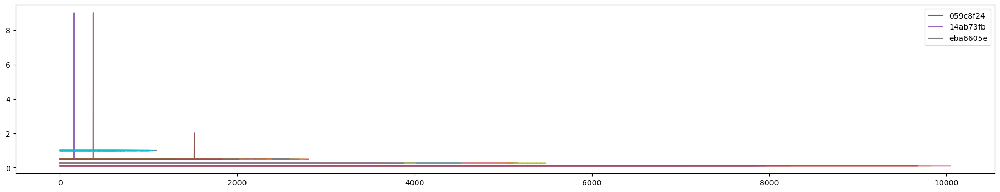

In [36]:
commond_diff_tvt = set()
tvt_anamolies = list()

plt.figure(figsize=(23, 4))
for well in well_names:
    tw = pd.read_csv(f'{train_data}/{well}__typewell.csv')
    # plt.plot(tw['TVT'])
    # plt.plot(tw['TVT'], tw['GR'])
    # plt.plot(tw['GR']) # GR vs index
    
    del_tvt = tw['TVT'].diff().dropna() 
    plt.plot(del_tvt)
    if np.std(del_tvt) > 0.01:
        plt.plot(del_tvt, label=well)
        plt.legend()
        tvt_anamolies.append(well)
    else:
        commond_diff_tvt.add(np.round(np.mean(del_tvt), 2))
        
    # plt.plot(tw['GR'].diff().dropna().rolling(window=10).mean())
    
    if well == well_names[:5]:
        break

commond_diff_tvt

In [37]:
vals = set()
for well in well_names:
    tw = pd.read_csv(f'{train_data}/{well}__typewell.csv')
    val = tw['TVT'][tw['Geology'] == 'ASTNL'].iloc[0]
    vals.add(val)
len(vals), len(well_names)

(55, 773)

## Testing-Data

In [38]:
test_data =  BASE_DIR + "/test/"
file_paths = sorted(glob.glob(test_data + "/*"))
file_paths

['../data/test/000d7d20__horizontal_well.csv',
 '../data/test/000d7d20__typewell.csv',
 '../data/test/00bbac68__horizontal_well.csv',
 '../data/test/00bbac68__typewell.csv',
 '../data/test/00e12e8b__horizontal_well.csv',
 '../data/test/00e12e8b__typewell.csv']

In [39]:
test_hw_csv = pd.read_csv(file_paths[0])
test_hw_csv.head()

,MD,X,Y,Z,GR,TVT_input
0,11467.0,2983525.16,1069022.09,-9258.57,115.692586,11236.02
1,11468.0,2983525.18,1069022.30,-9259.55,115.584293,11237.05
2,11469.0,2983525.20,1069022.52,-9260.52,135.446960,11238.09
3,11470.0,2983525.22,1069022.73,-9261.50,140.401346,11239.12
4,11471.0,2983525.25,1069022.95,-9262.47,111.270638,11240.15


In [40]:
test_hw_csv.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5278 entries, 0 to 5277
Data columns (total 6 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   MD         5278 non-null   float64
 1   X          5278 non-null   float64
 2   Y          5278 non-null   float64
 3   Z          5278 non-null   float64
 4   GR         3020 non-null   float64
 5   TVT_input  1442 non-null   float64
dtypes: float64(6)
memory usage: 247.5 KB


In [41]:
test_tw_csv = pd.read_csv(file_paths[1])
test_tw_csv.head()

,TVT,GR
0,11223.95,126.11
1,11224.45,128.22
2,11224.95,128.72
3,11225.45,128.12
4,11225.95,125.29
